In [19]:
#Practica 3_ Realizado por Angel Antolin

import pandas as pd
import numpy as np

from sklearn.datasets import fetch_openml
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import graphviz



# ------------------------------PARTE 1-----------------------------------------------
## ------------Ejercicio Presion------------------

In [20]:
#CSV con los datos de la presion
tabla_presion = pd.read_csv("./presion.csv")
tabla_presion

,Presión,Clase
0,40,+
1,48,+
2,60,-
3,72,-
4,80,-
5,90,+


In [21]:
#Sacar arbol, profundidad 1 para quedarse con la primera cota y la que maximiza la ganancia
df_presion = pd.DataFrame(tabla_presion)

X = df_presion[['Presión']]
Y = df_presion['Clase']


arbol_presion = DecisionTreeClassifier(criterion='entropy', max_depth=1)

arbol_presion.fit(X,Y)



,criterion,'entropy'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [22]:
#Mostrar Grafico
export_graphviz(arbol_presion, 
                out_file='arbol_presion.dot', 
                feature_names= X.columns,
                class_names = ['Falso', 'Verdadero'])

!dot -Tpng arbol_presion.dot -o arbol_presion.png -Gdpi=300

# ** ARBOL PRESION **
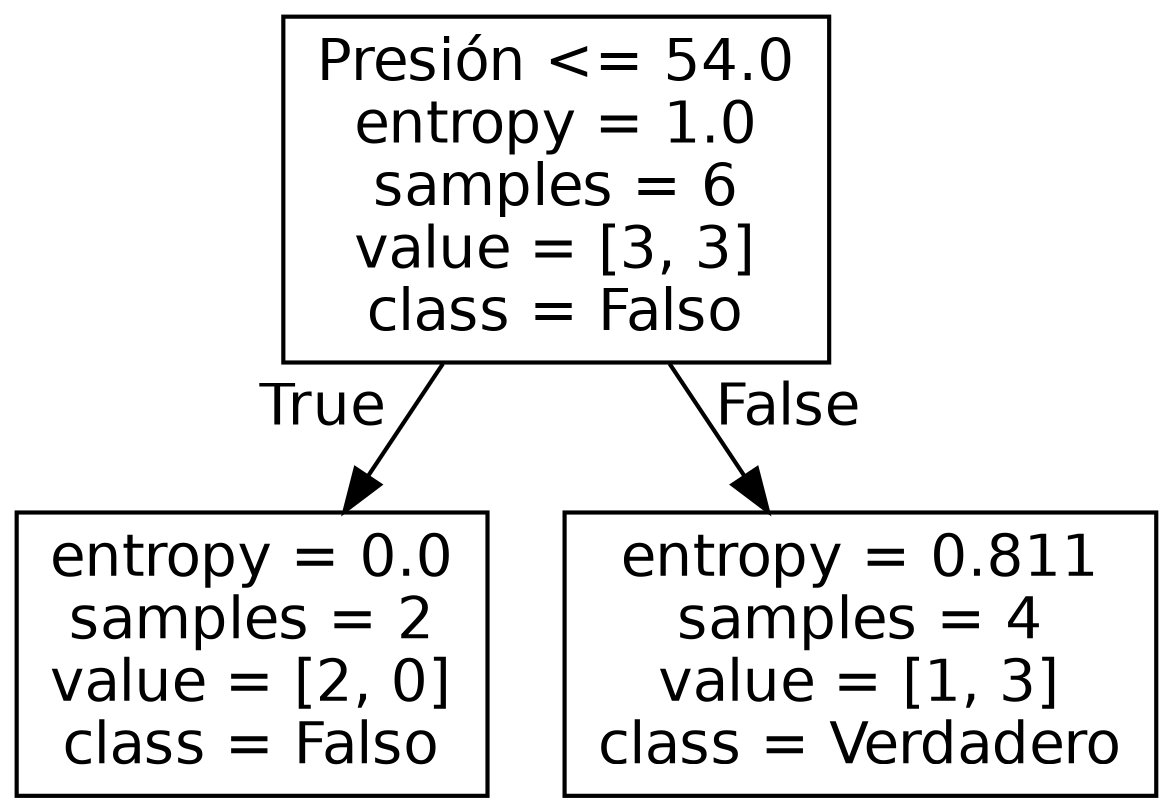

In [23]:
#Obtener el nodo raiz, que coincide con la cota obtenida
cota = arbol_presion.tree_.threshold[0]
cota

np.float64(54.0)

## ------------Ejercicio Edades------------------

In [24]:
#Descargar dataset

dataset = fetch_openml(data_id=1412, as_frame = True, parser= 'auto')

df = dataset.frame

df.columns

#Sacar tabla solo con edad y variable objetivo
tabla_edades = df[['age', 'OS_event']]

tabla_edades

,age,OS_event
0,55,1
1,38,0
2,30,0
3,64,0
4,63,0
...,...,...
221,64,0
222,61,0
223,58,0
224,49,0


In [25]:
df_edad = pd.DataFrame(tabla_edades)

X = df_edad[['age']]
Y = df_edad['OS_event']

#Crear el arbol con 8 grupos de edades para sacar 7 cotas

arbol_edad = DecisionTreeClassifier(criterion='entropy', max_leaf_nodes=8)

arbol_edad.fit(X,Y)


,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,8
,min_impurity_decrease,0.0
,class_weight,None


In [26]:
#Mostrar Grafico
export_graphviz(arbol_edad, 
                out_file='arbol_edad.dot', 
                feature_names= X.columns,
                class_names = ['Falso', 'Verdadero'])

!dot -Tpng arbol_edad.dot -o arbol_edad.png -Gdpi=300

# ** ARBOL EDADES **
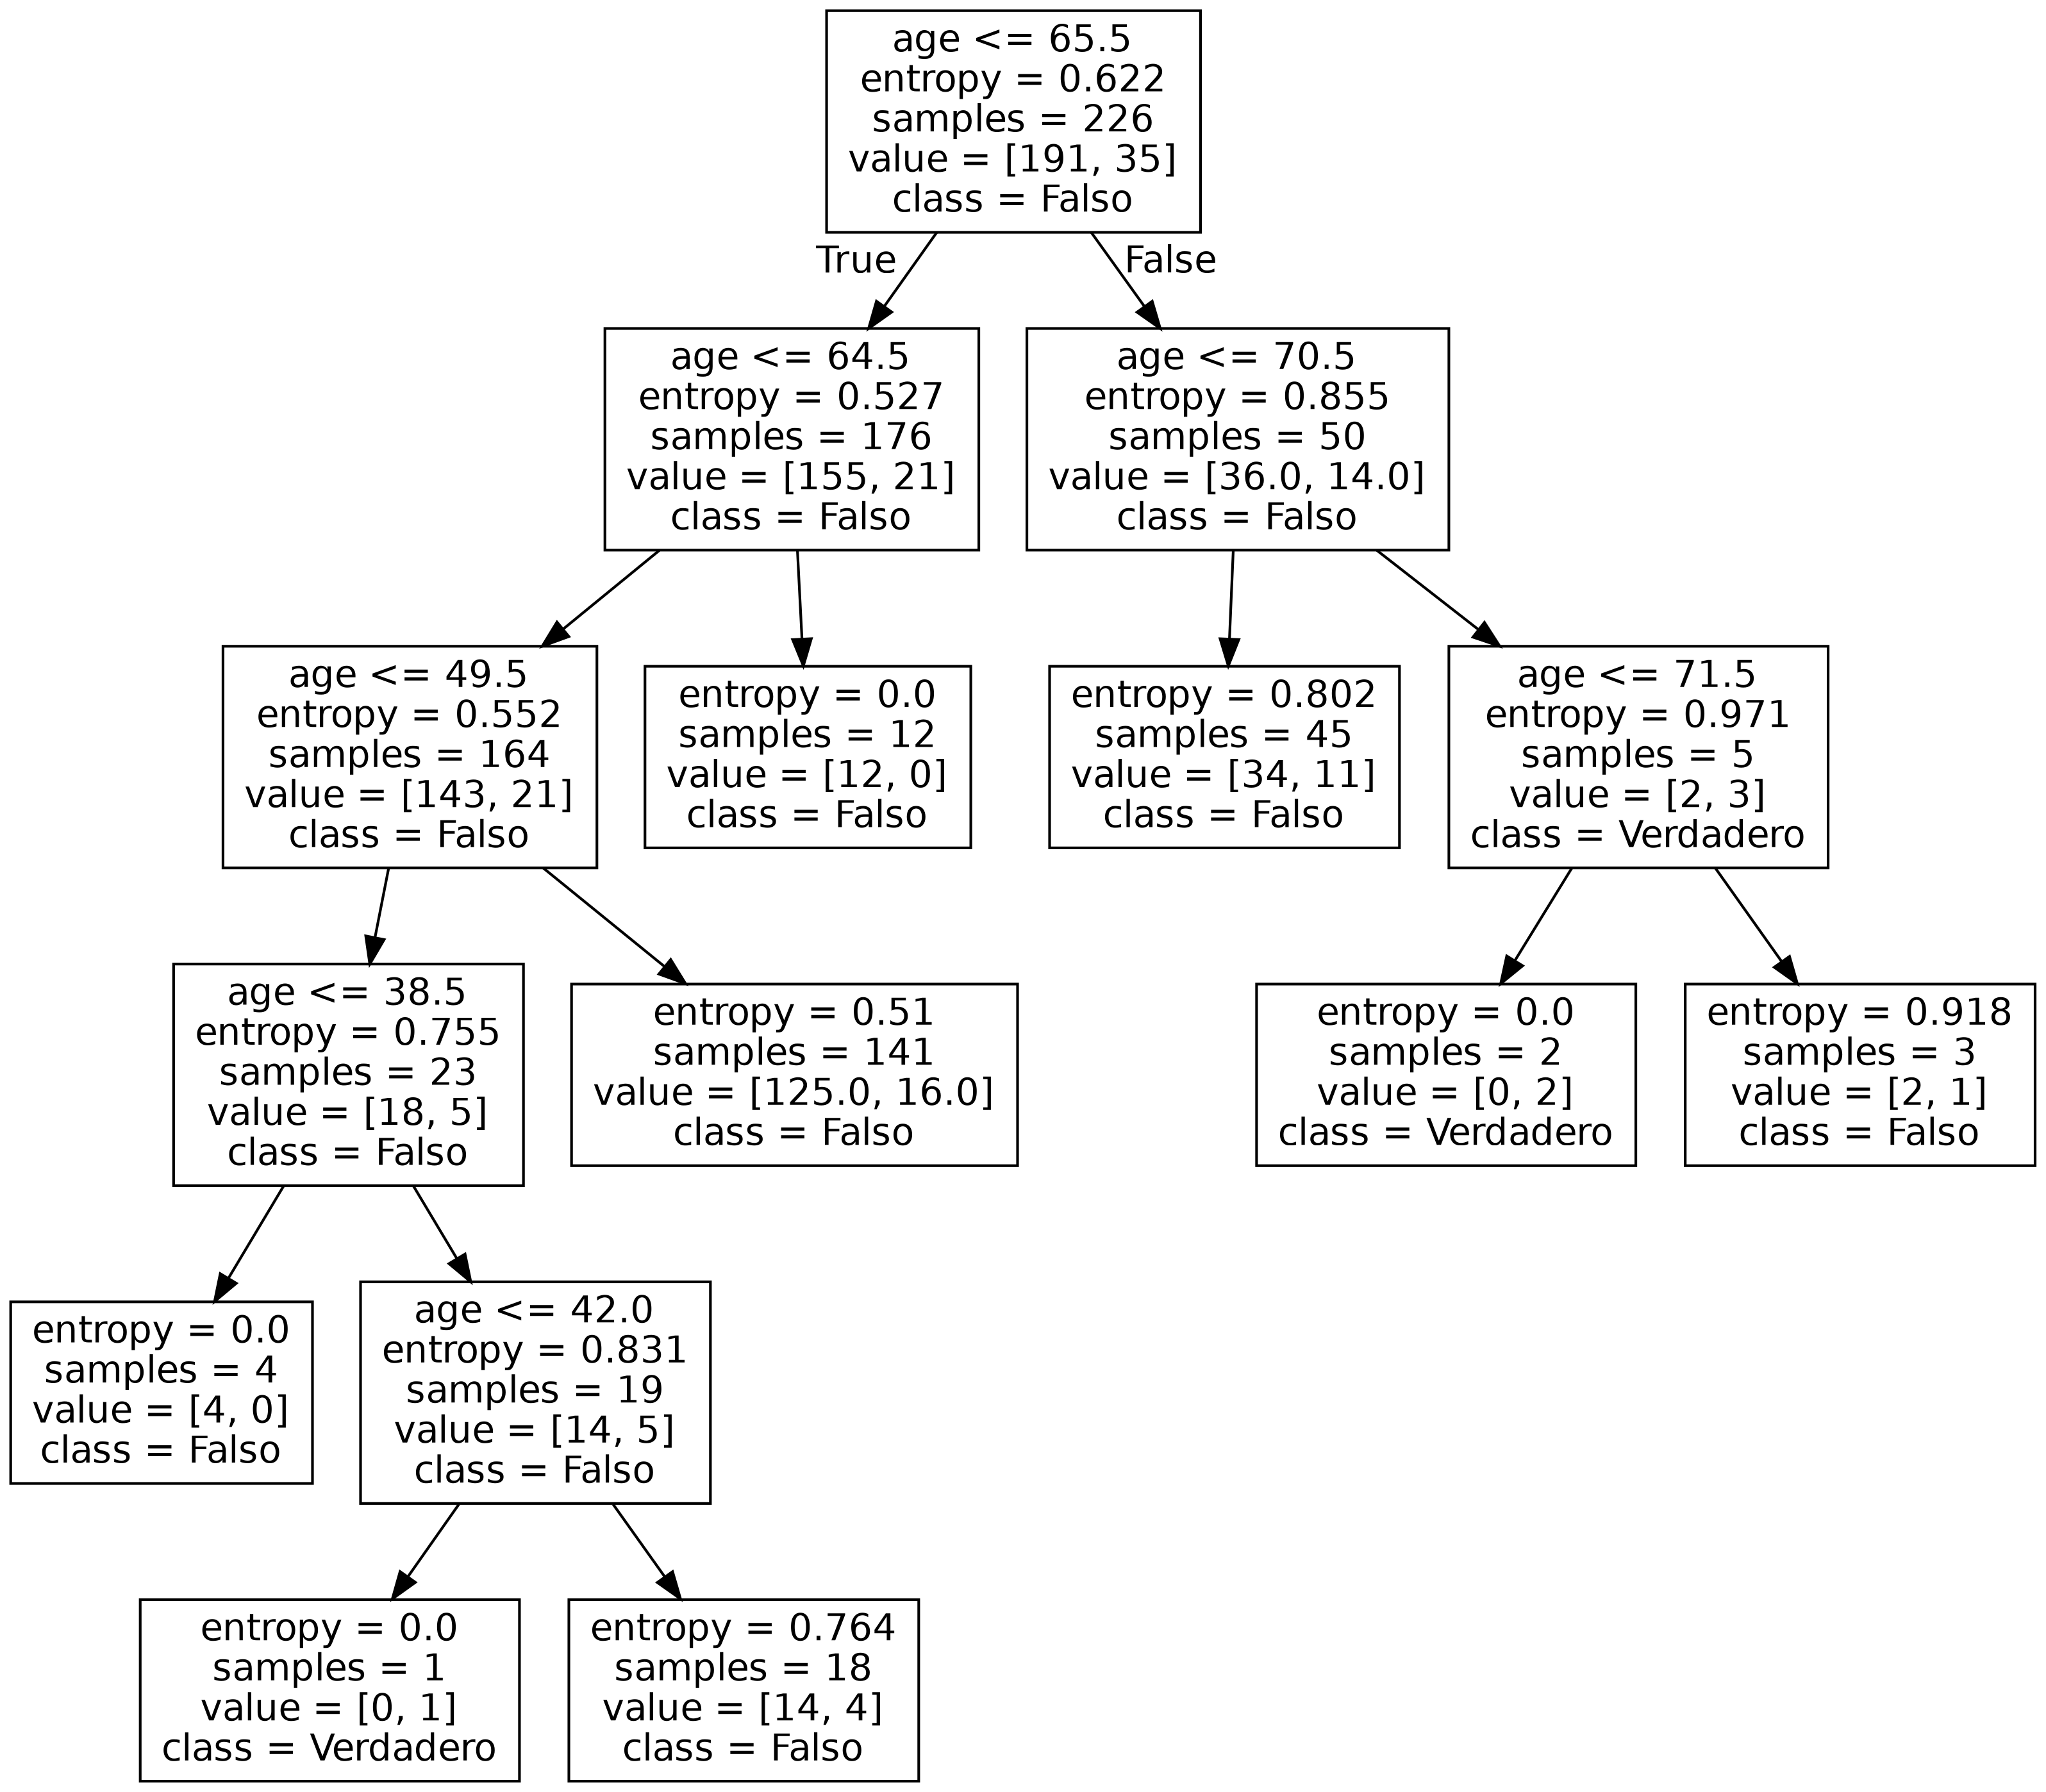

In [27]:
#Imprimir cotas
cotas = arbol_edad.tree_.threshold
cotas


array([65.5, 64.5, 70.5, 49.5, -2. , -2. , 71.5, -2. , -2. , 38.5, -2. ,
       -2. , 42. , -2. , -2. ])

In [28]:
cotas_ordenadas = np.sort(cotas)
cotas_ordenadas

array([-2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. , 38.5, 42. , 49.5,
       64.5, 65.5, 70.5, 71.5])

In [29]:
#---------COTAS DE LA EDAD, eliminando hojas que no hacen corte------#
cotas_edad = []
for cota in cotas_ordenadas:
    if(cota != -2):
        cotas_edad.append(cota)
cotas_edad

[np.float64(38.5),
 np.float64(42.0),
 np.float64(49.5),
 np.float64(64.5),
 np.float64(65.5),
 np.float64(70.5),
 np.float64(71.5)]

# ------------------------------------------ PARTE II -----------------------------------------

In [30]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
thoracic_surgery_data = fetch_ucirepo(id=277) 
  
# data (as pandas dataframes) 
X = thoracic_surgery_data.data.features 
y = thoracic_surgery_data.data.targets 
  
# metadata 
print(thoracic_surgery_data.metadata) 
  
# variable information 
print(thoracic_surgery_data.variables) 


{'uci_id': 277, 'name': 'Thoracic Surgery Data', 'repository_url': 'https://archive.ics.uci.edu/dataset/277/thoracic+surgery+data', 'data_url': 'https://archive.ics.uci.edu/static/public/277/data.csv', 'abstract': 'The data is dedicated to classification problem related to the post-operative life expectancy in the lung cancer patients: class 1 - death within one year after surgery, class 2 - survival.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 470, 'num_features': 16, 'feature_types': ['Integer', 'Real'], 'demographics': ['Age'], 'target_col': ['Risk1Yr'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5Z60N', 'creators': ['Marek Lubicz', 'Konrad Pawelczyk', 'Adam Rzechonek', 'Jerzy Kolodziej'], 'intro_paper': {'ID': 290, 'type': 'NATIVE', 'title': 'Boosted SVM for extracting rules from imb

In [31]:
#Concatenar para tener un unico dataframe
df_pacientes = pd.concat([X, y], axis=1)

df_pacientes.to_csv('datos_pacientes.csv', index=False)

### 1. Por qué no se puede aplicar directamente ID3.

Porque el algoritmo Divide y Vencerás de ID3 depende de que los atributos sean discretos,
pero en el dataset tenemos atributos continuos como la edad del paciente.

### -----------------EJERCICIO 2-----------------------------

In [35]:
#Abrir CSV y guardar columnas
df_original = pd.read_csv('datos_pacientes.csv')
columnas_originales = set(df_original.columns)

objetivo = 'Risk1Yr'


texto_arbol_completo = """=== Run information ===

Scheme:       weka.classifiers.trees.J48 -U -M 2
Relation:     datos_pacientes
Instances:    470
Attributes:   17
              DGN
              PRE4
              PRE5
              PRE6
              PRE7
              PRE8
              PRE9
              PRE10
              PRE11
              PRE14
              PRE17
              PRE19
              PRE25
              PRE30
              PRE32
              AGE
              Risk1Yr
Test mode:    split 66.0% train, remainder test

=== Classifier model (full training set) ===

J48 unpruned tree
------------------

PRE9 = F
|   PRE17 = F
|   |   DGN = DGN2
|   |   |   PRE30 = T
|   |   |   |   PRE10 = T
|   |   |   |   |   PRE6 = PRZ1
|   |   |   |   |   |   PRE14 = OC14: F (3.0)
|   |   |   |   |   |   PRE14 = OC12
|   |   |   |   |   |   |   PRE8 = F: T (6.0/2.0)
|   |   |   |   |   |   |   PRE8 = T: F (6.0/1.0)
|   |   |   |   |   |   PRE14 = OC11: F (5.0/1.0)
|   |   |   |   |   |   PRE14 = OC13: F (2.0)
|   |   |   |   |   PRE6 = PRZ0: T (2.0)
|   |   |   |   |   PRE6 = PRZ2: F (4.0/1.0)
|   |   |   |   PRE10 = F: F (10.0/1.0)
|   |   |   PRE30 = F: F (6.0)
|   |   DGN = DGN3
|   |   |   PRE7 = F
|   |   |   |   PRE14 = OC14: F (7.0/3.0)
|   |   |   |   PRE14 = OC12
|   |   |   |   |   PRE30 = T
|   |   |   |   |   |   PRE10 = T
|   |   |   |   |   |   |   PRE6 = PRZ1
|   |   |   |   |   |   |   |   PRE25 = F
|   |   |   |   |   |   |   |   |   PRE11 = T: F (16.0/1.0)
|   |   |   |   |   |   |   |   |   PRE11 = F
|   |   |   |   |   |   |   |   |   |   PRE8 = F: F (67.0/10.0)
|   |   |   |   |   |   |   |   |   |   PRE8 = T
|   |   |   |   |   |   |   |   |   |   |   PRE4 <= 2.88: T (3.0/1.0)
|   |   |   |   |   |   |   |   |   |   |   PRE4 > 2.88: F (4.0)
|   |   |   |   |   |   |   |   PRE25 = T: F (2.0)
|   |   |   |   |   |   |   PRE6 = PRZ0: F (2.0)
|   |   |   |   |   |   |   PRE6 = PRZ2: F (4.0)
|   |   |   |   |   |   PRE10 = F: F (30.0/1.0)
|   |   |   |   |   PRE30 = F: F (22.0)
|   |   |   |   PRE14 = OC11: F (121.0/7.0)
|   |   |   |   PRE14 = OC13: F (6.0/2.0)
|   |   |   PRE7 = T
|   |   |   |   PRE10 = T: F (13.0/2.0)
|   |   |   |   PRE10 = F
|   |   |   |   |   PRE14 = OC14: T (1.0)
|   |   |   |   |   PRE14 = OC12: T (2.0)
|   |   |   |   |   PRE14 = OC11: F (2.0)
|   |   |   |   |   PRE14 = OC13: T (0.0)
|   |   DGN = DGN4
|   |   |   PRE11 = T
|   |   |   |   PRE4 <= 2.66: T (3.0/1.0)
|   |   |   |   PRE4 > 2.66: F (2.0)
|   |   |   PRE11 = F
|   |   |   |   PRE14 = OC14: F (0.0)
|   |   |   |   PRE14 = OC12
|   |   |   |   |   PRE5 <= 2.04
|   |   |   |   |   |   AGE <= 70: T (3.0/1.0)
|   |   |   |   |   |   AGE > 70: F (2.0)
|   |   |   |   |   PRE5 > 2.04: F (19.0)
|   |   |   |   PRE14 = OC11: F (10.0)
|   |   |   |   PRE14 = OC13: F (1.0)
|   |   DGN = DGN8: F (2.0/1.0)
|   |   DGN = DGN5
|   |   |   PRE8 = F
|   |   |   |   PRE14 = OC14: T (0.0)
|   |   |   |   PRE14 = OC12: F (3.0/1.0)
|   |   |   |   PRE14 = OC11
|   |   |   |   |   PRE10 = T: T (2.0)
|   |   |   |   |   PRE10 = F: F (3.0/1.0)
|   |   |   |   PRE14 = OC13: T (1.0)
|   |   |   PRE8 = T: F (3.0)
|   |   DGN = DGN6: F (4.0)
|   |   DGN = DGN1: F (1.0)
|   PRE17 = T
|   |   PRE8 = F
|   |   |   AGE <= 65
|   |   |   |   PRE11 = T: T (3.0)
|   |   |   |   PRE11 = F
|   |   |   |   |   PRE14 = OC14: T (1.0)
|   |   |   |   |   PRE14 = OC12
|   |   |   |   |   |   AGE <= 62: F (7.0/1.0)
|   |   |   |   |   |   AGE > 62: T (2.0)
|   |   |   |   |   PRE14 = OC11: F (5.0)
|   |   |   |   |   PRE14 = OC13: F (0.0)
|   |   |   AGE > 65: F (12.0)
|   |   PRE8 = T: T (4.0/1.0)
PRE9 = T
|   PRE11 = T: T (2.0)
|   PRE11 = F
|   |   PRE6 = PRZ1
|   |   |   PRE10 = T
|   |   |   |   PRE7 = F
|   |   |   |   |   PRE8 = F: F (11.0)
|   |   |   |   |   PRE8 = T
|   |   |   |   |   |   DGN = DGN2: F (2.0)
|   |   |   |   |   |   DGN = DGN3: T (3.0/1.0)
|   |   |   |   |   |   DGN = DGN4: F (0.0)
|   |   |   |   |   |   DGN = DGN8: F (0.0)
|   |   |   |   |   |   DGN = DGN5: F (0.0)
|   |   |   |   |   |   DGN = DGN6: F (0.0)
|   |   |   |   |   |   DGN = DGN1: F (0.0)
|   |   |   |   PRE7 = T: F (2.0/1.0)
|   |   |   PRE10 = F: F (5.0)
|   |   PRE6 = PRZ0: T (4.0/1.0)
|   |   PRE6 = PRZ2: F (2.0/1.0)

Number of Leaves  : 	64

Size of the tree : 	102


Time taken to build model: 0.05 seconds

=== Evaluation on test split ===

Time taken to test model on test split: 0.01 seconds

=== Summary ===

Correctly Classified Instances         123               76.875  %
Incorrectly Classified Instances        37               23.125  %
Kappa statistic                          0.047 
Mean absolute error                      0.2586
Root mean squared error                  0.4423
Relative absolute error                 99.5075 %
Root relative squared error            119.7396 %
Total Number of Instances              160     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0,888    0,846    0,844      0,888    0,865      0,048    0,593     0,870     F
                 0,154    0,112    0,211      0,154    0,178      0,048    0,593     0,197     T
Weighted Avg.    0,769    0,727    0,741      0,769    0,754      0,048    0,593     0,760     

=== Confusion Matrix ===

   a   b   <-- classified as
 119  15 |   a = F
  22   4 |   b = T
"""

arbol_texto = texto_arbol_completo.split('\n')



#Recorrer el texto hasta el arbol y me quedo con los atributos que aparezcan

atributos_usados = set()
leyendo_arbol = False

for linea in arbol_texto:

    #Ha llegado al arbol
    if "J48 unpruned tree" in linea:
        leyendo_arbol = True
    
    #Ha terminado el arbol
    if "Number of Leaves" in linea:
        break
    
    #Lee cada linea del arbol en busca de los atributos que usa
    if leyendo_arbol:
        if "<=" in linea or ">=" in linea or "<" in linea or ">" in linea or "=" in linea:

            #Las lineas con atributos usados tienen un simbolo de los del if, quitar primero espacios
            linea_limpia = linea.replace("|","").strip()
            palabras = linea_limpia.split()
            atributo = palabras[0]
            atributos_usados.add(atributo)

atributos_usados.add(objetivo)
atributos_no_usados = columnas_originales - atributos_usados

atributos_no_usados


{'PRE19', 'PRE32'}

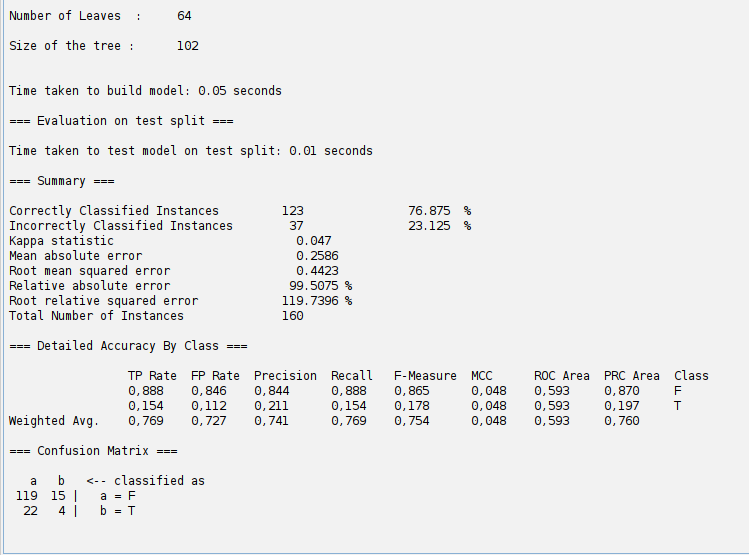

### ¿Se podría prescindir de algún atributo?

Sí, los atributos PRE19 y PRE32 no son utilizados a la hora de crear el árbol. 
Este árbol ha clasificado correctamente el 76.875% de las instancias.

In [36]:
df_nuevo = df_original.drop(columns = list(atributos_no_usados))
df_nuevo.to_csv('datos_pacientes_nuevo.csv', index=False)

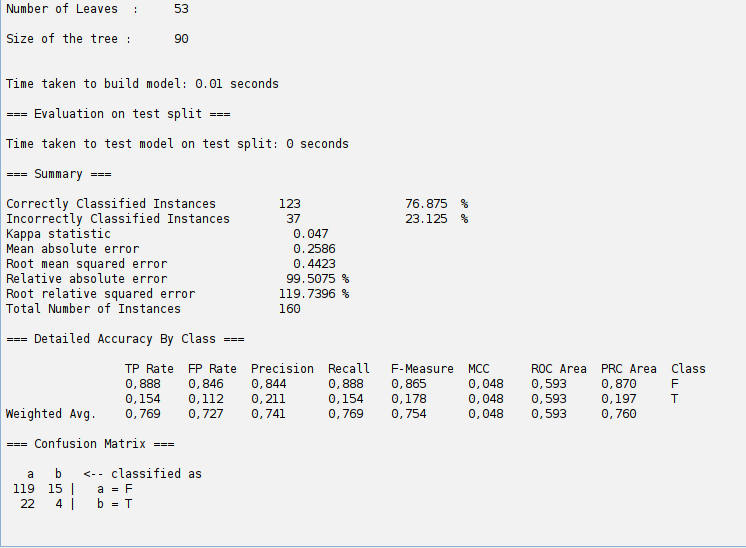

Se observa que el porcentaje es el mismo que cuando teníamos los 2 atributos eliminados, luego efectivamente podiamos prescindir de esos atributos. De esta manera nos queda un árbol más pequeño y que consigue el mismo resultado.

### 3. Habrá notado que cuando se usa algún atributo numérico,
### implícitamente se aplica una discretización al plantear las
### diferentes ramas del árbol a partir de él. ¿Por qué es más
### eficiente esta técnica que la aplicada en PARTE I?

Porque en la PARTE I se aplicaba una discretización global, pues solo se usaba la columna entera de Edad para hacer cortes antes de que el algoritmo aprendiera, haciendo los cortes a ciegas y provocando que el árbol use esos intervalos de edad para todos los pacientes sin tener en cuenta sus otros síntomas.
En este caso, el árbol lo hace de manera dinámica e independiente sobre cada rama, permitiendo que adapte el umbral númerico al subgrupo exacto de pacientes que analiza en ese momento.

### ----------------- EJERCICIO 4 ------------------

In [38]:
df_discretizado = pd.read_csv('datos_pacientes_nuevo.csv')


texto_arbol_completo = """=== Run information ===

Scheme:       weka.classifiers.trees.J48 -U -M 2
Relation:     datos_pacientes_nuevo
Instances:    470
Attributes:   15
              DGN
              PRE4
              PRE5
              PRE6
              PRE7
              PRE8
              PRE9
              PRE10
              PRE11
              PRE14
              PRE17
              PRE25
              PRE30
              AGE
              Risk1Yr
Test mode:    split 66.0% train, remainder test

=== Classifier model (full training set) ===

J48 unpruned tree
------------------

DGN = DGN2
|   PRE7 = F
|   |   PRE25 = F
|   |   |   PRE14 = OC14
|   |   |   |   PRE5 <= 2.84: F (4.0)
|   |   |   |   PRE5 > 2.84: T (3.0)
|   |   |   PRE14 = OC12
|   |   |   |   PRE10 = T
|   |   |   |   |   PRE30 = T
|   |   |   |   |   |   PRE8 = F: T (7.0/2.0)
|   |   |   |   |   |   PRE8 = T: F (7.0/1.0)
|   |   |   |   |   PRE30 = F: F (3.0)
|   |   |   |   PRE10 = F: F (9.0)
|   |   |   PRE14 = OC11: F (11.0/1.0)
|   |   |   PRE14 = OC13: F (4.0/1.0)
|   |   PRE25 = T: F (2.0/1.0)
|   PRE7 = T: F (2.0)
DGN = DGN3
|   PRE7 = F
|   |   PRE9 = F
|   |   |   PRE30 = T
|   |   |   |   PRE17 = F
|   |   |   |   |   PRE14 = OC14
|   |   |   |   |   |   AGE <= 50: T (3.0/1.0)
|   |   |   |   |   |   AGE > 50: F (3.0)
|   |   |   |   |   PRE14 = OC12
|   |   |   |   |   |   PRE10 = T
|   |   |   |   |   |   |   PRE6 = PRZ1
|   |   |   |   |   |   |   |   PRE25 = F
|   |   |   |   |   |   |   |   |   PRE11 = T: F (16.0/1.0)
|   |   |   |   |   |   |   |   |   PRE11 = F
|   |   |   |   |   |   |   |   |   |   PRE8 = F: F (67.0/10.0)
|   |   |   |   |   |   |   |   |   |   PRE8 = T
|   |   |   |   |   |   |   |   |   |   |   PRE4 <= 2.88: T (3.0/1.0)
|   |   |   |   |   |   |   |   |   |   |   PRE4 > 2.88: F (4.0)
|   |   |   |   |   |   |   |   PRE25 = T: F (2.0)
|   |   |   |   |   |   |   PRE6 = PRZ0: F (2.0)
|   |   |   |   |   |   |   PRE6 = PRZ2: F (4.0)
|   |   |   |   |   |   PRE10 = F: F (30.0/1.0)
|   |   |   |   |   PRE14 = OC11: F (102.0/7.0)
|   |   |   |   |   PRE14 = OC13
|   |   |   |   |   |   AGE <= 58: T (2.0)
|   |   |   |   |   |   AGE > 58: F (3.0)
|   |   |   |   PRE17 = T
|   |   |   |   |   PRE5 <= 1.44: T (2.0)
|   |   |   |   |   PRE5 > 1.44: F (16.0/3.0)
|   |   |   PRE30 = F
|   |   |   |   PRE14 = OC14: T (1.0)
|   |   |   |   PRE14 = OC12: F (24.0)
|   |   |   |   PRE14 = OC11: F (22.0)
|   |   |   |   PRE14 = OC13: F (1.0)
|   |   PRE9 = T
|   |   |   PRE11 = T: T (2.0)
|   |   |   PRE11 = F
|   |   |   |   PRE8 = F: F (12.0/1.0)
|   |   |   |   PRE8 = T
|   |   |   |   |   PRE10 = T: T (3.0/1.0)
|   |   |   |   |   PRE10 = F: F (2.0)
|   PRE7 = T
|   |   PRE11 = T: T (2.0)
|   |   PRE11 = F
|   |   |   PRE14 = OC14: T (1.0)
|   |   |   PRE14 = OC12
|   |   |   |   PRE10 = T
|   |   |   |   |   PRE8 = F
|   |   |   |   |   |   AGE <= 59: T (3.0/1.0)
|   |   |   |   |   |   AGE > 59: F (2.0)
|   |   |   |   |   PRE8 = T: F (4.0)
|   |   |   |   PRE10 = F: T (2.0)
|   |   |   PRE14 = OC11: F (6.0)
|   |   |   PRE14 = OC13: F (3.0)
DGN = DGN4
|   PRE5 <= 2.2
|   |   PRE30 = T
|   |   |   PRE6 = PRZ1
|   |   |   |   AGE <= 61: T (2.0)
|   |   |   |   AGE > 61: F (9.0/2.0)
|   |   |   PRE6 = PRZ0: T (1.0)
|   |   |   PRE6 = PRZ2: T (2.0)
|   |   PRE30 = F: F (4.0)
|   PRE5 > 2.2: F (29.0)
DGN = DGN8: F (2.0/1.0)
DGN = DGN5
|   PRE7 = F
|   |   PRE11 = T: F (4.0/1.0)
|   |   PRE11 = F: T (8.0/2.0)
|   PRE7 = T: F (3.0)
DGN = DGN6: F (4.0)
DGN = DGN1: F (1.0)

Number of Leaves  : 	53

Size of the tree : 	90


Time taken to build model: 0.02 seconds

=== Evaluation on test split ===

Time taken to test model on test split: 0 seconds

=== Summary ===

Correctly Classified Instances         123               76.875  %
Incorrectly Classified Instances        37               23.125  %
Kappa statistic                          0.047 
Mean absolute error                      0.2586
Root mean squared error                  0.4423
Relative absolute error                 99.5075 %
Root relative squared error            119.7396 %
Total Number of Instances              160     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0,888    0,846    0,844      0,888    0,865      0,048    0,593     0,870     F
                 0,154    0,112    0,211      0,154    0,178      0,048    0,593     0,197     T
Weighted Avg.    0,769    0,727    0,741      0,769    0,754      0,048    0,593     0,760     

=== Confusion Matrix ===

   a   b   <-- classified as
 119  15 |   a = F
  22   4 |   b = T
"""

arbol_texto = texto_arbol_completo.split('\n')


#Diccionario para guardar cada atributo con las cotas que usaba J48
cotas_atributo = {}


#Reutilizo el codigo anterior con un pequeño cambio para guardar el atributo con su valor
#usado para hacer la cota
leyendo_arbol = False

for linea in arbol_texto:

    #Ha llegado al arbol
    if "J48 unpruned tree" in linea:
        leyendo_arbol = True
    
    #Ha terminado el arbol
    if "Number of Leaves" in linea:
        break
    
    #Lee cada linea del arbol en busca de los atributos que usa
    if leyendo_arbol:
        if "<=" in linea or ">=" in linea or "<" in linea or ">" in linea or "=" in linea:

            #Las lineas con atributos usados tienen un simbolo de los del if, quitar primero espacios
            linea_limpia = linea.replace("|","").strip()
            palabras = linea_limpia.split()
            atributo = palabras[0]
            valor = palabras [2].replace(":","")

            #Intentar guardar el valor numerico con el atributo, si no se puede (no era numerico) pasa 
            try:

                valor_numerico = float(valor)

                if atributo not in cotas_atributo:
                    cotas_atributo[atributo] = set()
                cotas_atributo[atributo].add(valor_numerico)

            except ValueError:
                pass

#Ordenar de menor a mayor las cotas de cada atributo
for atributo, cotas in cotas_atributo.items():

    cotas_ordenadas = sorted(list(cotas))
    cotas_atributo[atributo] = cotas_ordenadas

#Aplicar la discretizacion y prepararla para que pueda ser usada por ID3
for atributo, cotas in cotas_atributo.items():

    if atributo in df_discretizado.columns:

        limites = [-np.inf] + cotas + [np.inf]
        df_discretizado[atributo] = pd.cut(df_discretizado[atributo], bins = limites).astype(str)
        

df_discretizado.to_csv('datos_pacientes_ID3.csv', index = False)

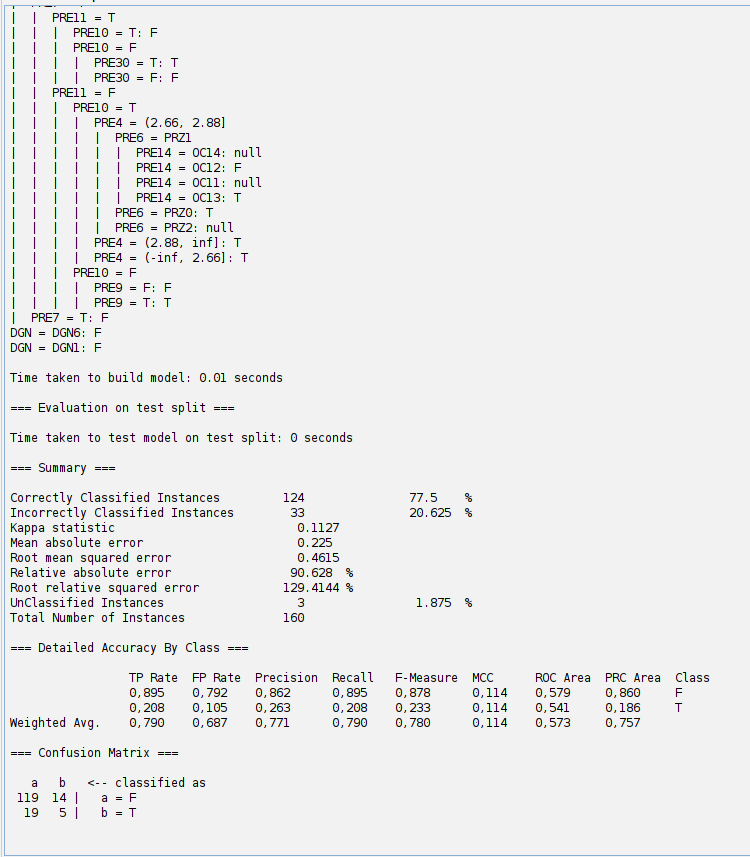

Al pasar el csv discretizado por el ID3 se observa que el porcentaje de aciertos ha subido al 77.5%, pero aparece que un 1.875% de las instancias no se han clasificado. Al ramificarse más provoca que aparezcan hojas vacías, provocando que aunque parezca que tiene mejor rendimiento, J48 sigue siendo mas robusto.